In [39]:
import numpy as np
import matplotlib.pyplot as plt
from dtaidistance import dtw

In [40]:
series1 = [1, 3, 6, 1]
series2 = [2, 5, 2, 9]

In [41]:
def dtw_custom(s1, s2):
    n, m = len(s1), len(s2)
    dtw_matrix = np.full((n+1, m+1), np.inf)
    dtw_matrix[0, 0] = 0

    for i in range(1, n+1):
        for j in range(1, m+1):
            cost = (s1[i-1] - s2[j-1]) ** 2
            last_min = min(
                dtw_matrix[i-1, j],
                dtw_matrix[i, j-1],
                dtw_matrix[i-1, j-1]
            )
            dtw_matrix[i, j] = cost + last_min

    i, j = n, m
    path = [(i-1, j-1)]
    while i > 1 or j > 1:
        steps = [
            (dtw_matrix[i-1, j-1], i-1, j-1),
            (dtw_matrix[i-1, j], i-1, j),
            (dtw_matrix[i, j-1], i, j-1)
        ]
        cost, i, j = min(steps)
        path.append((i-1, j-1))
    path.reverse()

    return np.sqrt(dtw_matrix[n, m]), path

In [42]:
dist_custom, path_custom = dtw_custom(series1, series2)
print(f"Custom DTW distance: {dist_custom:.3f}")
print(f"Custom alignment path: {path_custom}")

Custom DTW distance: 8.246
Custom alignment path: [(0, 0), (1, 0), (2, 1), (3, 2), (3, 3)]


In [43]:
dist_lib = dtw.distance(series1, series2)
path_lib = dtw.warping_path(series1, series2)
print(f"Library DTW distance: {dist_lib:.3f}")
print(f"Library alignment path: {path_lib}")

Library DTW distance: 8.246
Library alignment path: [(0, 0), (1, 0), (2, 1), (3, 2), (3, 3)]


In [44]:
assert np.isclose(dist_custom, dist_lib), "DTW distances do not match!"
print("DTW distances match!")

DTW distances match!


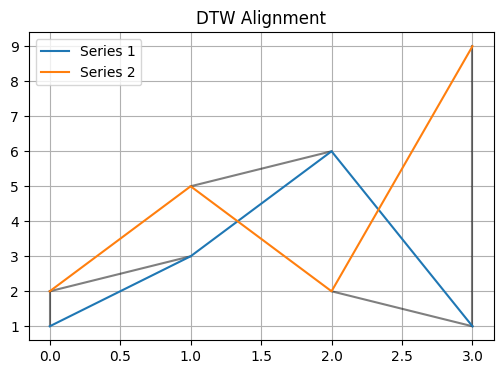

In [45]:
def plot_alignment(series1, series2, path):
    plt.figure(figsize=(6, 4))
    for (i, j) in path:
        if i >= 0 and j >= 0:
            plt.plot([i, j], [series1[i], series2[j]], 'k-', alpha=0.5)
    plt.plot(series1, label='Series 1')
    plt.plot(series2, label='Series 2')
    plt.legend()
    plt.title('DTW Alignment')
    plt.grid(True)
    plt.show()

plot_alignment(series1, series2, path_custom)